# Rossmann Store Sales — Phase 4: Entity Embeddings + MLP

Goal: test whether a fundamentally different modeling paradigm — a small neural network that learns its own dense representation of `Store` (and other categoricals) via embedding tables, rather than one-hot (Ridge) or target-encoding (trees) — can separate itself from Phase 3, where the best tree model (HGB) only beat Phase 1's baseline lookup table by ~4% relative RMSPE despite substantial feature-engineering effort. This is the same entity-embeddings approach used in the actual 3rd-place solution to the original Rossmann Kaggle competition (Guo & Berkhahn, 2016).

Same feature set as Phase 3 (identical lag/rolling features, identical frozen-cutoff train/val split) so the comparison isolates the modeling paradigm, not the inputs. Bar to beat: Phase 3 HGB, RMSPE 0.1412. Uses `train.csv`/`store.csv` only — `test.csv` stays unseen until Phase 5.

In [1]:
import json
import numpy as np
import pandas as pd
import torch
import plotly.express as px
import plotly.io as pio
pio.templates.default = "plotly_white"

from rossmann_features import (
    prepare_store_table, add_features, NUMERIC_COLS,
    add_rolling_features_training, add_rolling_features_frozen, ROLLING_WINDOWS,
    add_yearago_lag, fit_store_dow_promo_mean, predict_store_dow_promo_mean,
    fit_store_target_encoding, add_store_target_encoding,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "-", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    pct_err = (y_true[mask] - y_pred[mask]) / y_true[mask]
    return float(np.sqrt(np.mean(pct_err ** 2)))

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
store = pd.read_csv("store.csv")
store_prepared = prepare_store_table(store)

with open("phase1_split_config.json") as f:
    split_cfg = json.load(f)
val_start = pd.Timestamp(split_cfg["val_start"])
train_fold = add_features(train[train["Date"] < val_start].copy(), store_prepared)
val_fold = add_features(train[train["Date"] >= val_start].copy(), store_prepared)
train_fold_open = train_fold[train_fold["Open"] == 1]
train_fit = train_fold[(train_fold["Open"] == 1) & (train_fold["Sales"] > 0)].copy()
print("train_fold:", train_fold["Date"].min().date(), "-", train_fold["Date"].max().date())
print("val_fold:  ", val_fold["Date"].min().date(), "-", val_fold["Date"].max().date())
print("train_fit rows:", len(train_fit))


device: cuda - NVIDIA GeForce GTX 1650 Ti


train_fold: 2013-01-01 - 2015-06-19
val_fold:   2015-06-20 - 2015-07-31
train_fit rows: 804056


In [2]:
# Identical lag/rolling/target-encoding pipeline as Phase 3 -- same fallback tables,
# same frozen-cutoff-vs-training-mode split -- so the NN sees the exact same information
# as the tree models. (StoreMeanLogSales is still computed here for completeness /
# reuse of the shared function, but the NN won't use it: an embedding IS the entity's
# own learned representation, so target-encoding Store as well would be redundant.)
sd_table = fit_store_dow_promo_mean(train_fold_open)
global_mean = train_fold_open["Sales"].mean()
store_encoding = fit_store_target_encoding(train_fold_open)
global_mean_log = np.log1p(train_fold_open["Sales"]).mean()

def build_dataset(df, mode, cutoff_date=None):
    if mode == "training":
        df = add_rolling_features_training(df)
    elif mode == "frozen":
        df = add_rolling_features_frozen(df, train_fold_open, cutoff_date)
    else:
        raise ValueError(mode)
    fallback = predict_store_dow_promo_mean(df, sd_table, global_mean)
    df = add_yearago_lag(df, train_fold_open, fallback)
    df = add_store_target_encoding(df, store_encoding, global_mean_log)
    return df

CUTOFF = train_fold["Date"].max()
train_fit_feat = build_dataset(train_fit, mode="training")
val_fold_feat = build_dataset(val_fold, mode="frozen", cutoff_date=CUTOFF)

LAG_COLS = [f"SalesRollMean{w}" for w in ROLLING_WINDOWS] + [f"CustomersRollMean{w}" for w in ROLLING_WINDOWS] + \
           ["SalesYearAgo", "HorizonDay"]
print("lag columns:", LAG_COLS)
print("NaN check train_fit_feat:", train_fit_feat[LAG_COLS].isna().sum().to_dict())
print("NaN check val_fold_feat:", val_fold_feat[LAG_COLS].isna().sum().to_dict())


lag columns: ['SalesRollMean7', 'SalesRollMean30', 'SalesRollMean90', 'CustomersRollMean7', 'CustomersRollMean30', 'CustomersRollMean90', 'SalesYearAgo', 'HorizonDay']
NaN check train_fit_feat: {'SalesRollMean7': 0, 'SalesRollMean30': 0, 'SalesRollMean90': 0, 'CustomersRollMean7': 0, 'CustomersRollMean30': 0, 'CustomersRollMean90': 0, 'SalesYearAgo': 0, 'HorizonDay': 0}
NaN check val_fold_feat: {'SalesRollMean7': 0, 'SalesRollMean30': 0, 'SalesRollMean90': 0, 'CustomersRollMean7': 0, 'CustomersRollMean30': 0, 'CustomersRollMean90': 0, 'SalesYearAgo': 0, 'HorizonDay': 0}


In [3]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

# nn.Embedding needs contiguous 0-indexed integer codes. OrdinalEncoder already produces
# those for known categories; unknown_value slots into one extra "unseen" row per table
# (train_fold_open spans the full store universe and multi-year date range, so in
# practice every val_fold category is already known -- this is a safety net, not a
# real gap). Store is included here as a plain categorical, NOT target-encoded: the
# whole point of this phase is to let the network learn its own Store representation.
# PromoMonthMod is left out -- it's NaN for any store without Promo2 (there's no
# PromoInterval to derive it from for those stores), and its information already flows
# through IsPromo2Active (in NN_NUMERIC_COLS), which is why Phase 3's tree feature set
# didn't use it directly either.
NN_CATEGORICAL_COLS = ["Store", "DayOfWeek", "Month", "StoreType", "Assortment", "StateHoliday"]
NN_NUMERIC_COLS = NUMERIC_COLS + LAG_COLS

cat_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int64)
train_cat_codes = cat_encoder.fit_transform(train_fit_feat[NN_CATEGORICAL_COLS])
val_cat_codes = cat_encoder.transform(val_fold_feat[NN_CATEGORICAL_COLS])

CARDINALITIES = [len(cats) + 1 for cats in cat_encoder.categories_]  # +1 slot for unknown_value=-1
UNKNOWN_SLOT = {col: len(cats) for col, cats in zip(NN_CATEGORICAL_COLS, cat_encoder.categories_)}
train_cat_codes = np.where(train_cat_codes == -1, np.array([UNKNOWN_SLOT[c] for c in NN_CATEGORICAL_COLS]), train_cat_codes)
val_cat_codes = np.where(val_cat_codes == -1, np.array([UNKNOWN_SLOT[c] for c in NN_CATEGORICAL_COLS]), val_cat_codes)
print("categorical columns:", NN_CATEGORICAL_COLS)
print("cardinalities (incl. unknown slot):", dict(zip(NN_CATEGORICAL_COLS, CARDINALITIES)))
print("unseen-category rows in val_fold:", (val_cat_codes == np.array([UNKNOWN_SLOT[c] for c in NN_CATEGORICAL_COLS])).sum())

num_scaler = StandardScaler()
train_num = num_scaler.fit_transform(train_fit_feat[NN_NUMERIC_COLS].to_numpy())
val_num = num_scaler.transform(val_fold_feat[NN_NUMERIC_COLS].to_numpy())

y_train_log = np.log1p(train_fit_feat["Sales"].to_numpy())
print("train_cat_codes shape:", train_cat_codes.shape, "| train_num shape:", train_num.shape)


categorical columns: ['Store', 'DayOfWeek', 'Month', 'StoreType', 'Assortment', 'StateHoliday']
cardinalities (incl. unknown slot): {'Store': 1116, 'DayOfWeek': 8, 'Month': 13, 'StoreType': 5, 'Assortment': 4, 'StateHoliday': 5}
unseen-category rows in val_fold: 0
train_cat_codes shape: (804056, 6) | train_num shape: (804056, 14)


In [4]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class RossmannDataset(Dataset):
    def __init__(self, cat_codes, num_feats, targets):
        self.cat_codes = torch.as_tensor(cat_codes, dtype=torch.long)
        self.num_feats = torch.as_tensor(num_feats, dtype=torch.float32)
        self.targets = torch.as_tensor(targets, dtype=torch.float32)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return self.cat_codes[idx], self.num_feats[idx], self.targets[idx]


# Store gets its own, larger embedding (20 dims -- the original entity-embeddings paper
# used 10; 20 leaves headroom for 1,115 stores without over-parameterizing a lookup
# problem into an overfitting risk). The small-cardinality columns get small, roughly
# cardinality/2-sized embeddings -- there just isn't much latent structure to capture
# in a 5-8 category column.
EMB_DIMS = {"Store": 20, "DayOfWeek": 4, "Month": 6, "StoreType": 3, "Assortment": 2, "StateHoliday": 2}

class EmbeddingMLP(nn.Module):
    def __init__(self, cardinalities, cat_cols, emb_dims, n_numeric):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, emb_dims[col]) for card, col in zip(cardinalities, cat_cols)
        ])
        emb_total = sum(emb_dims[col] for col in cat_cols)
        self.num_bn = nn.BatchNorm1d(n_numeric)
        in_features = emb_total + n_numeric
        self.mlp = nn.Sequential(
            nn.Linear(in_features, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, cat_codes, num_feats):
        embedded = [emb(cat_codes[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat(embedded + [self.num_bn(num_feats)], dim=1)
        return self.mlp(x).squeeze(-1)


# Smoke test on a small batch before committing to a full training loop.
model = EmbeddingMLP(CARDINALITIES, NN_CATEGORICAL_COLS, EMB_DIMS, len(NN_NUMERIC_COLS)).to(device)
sample_cat = torch.as_tensor(train_cat_codes[:8], dtype=torch.long).to(device)
sample_num = torch.as_tensor(train_num[:8], dtype=torch.float32).to(device)
with torch.no_grad():
    out = model(sample_cat, sample_num)
print("smoke test output shape:", out.shape)
print("total params:", sum(p.numel() for p in model.parameters()))


smoke test output shape: torch.Size([8])
total params: 77916


In [5]:
# Internal time-based split WITHIN train_fold for epoch selection, matching Phase 3's
# discipline exactly (its own frozen cutoff, separate from CUTOFF, so picking the
# epoch count never touches the real val_fold).
inner_val_start = train_fold["Date"].max() - pd.Timedelta(days=41)
inner_cutoff = inner_val_start - pd.Timedelta(days=1)
inner_train_raw = train_fit[train_fit["Date"] < inner_val_start].copy()
inner_val_raw = train_fold[(train_fold["Date"] >= inner_val_start) & (train_fold["Open"] == 1)].copy()

inner_history_open = train_fold_open[train_fold_open["Date"] <= inner_cutoff]
inner_sd_table = fit_store_dow_promo_mean(inner_history_open)
inner_global_mean = inner_history_open["Sales"].mean()
inner_store_encoding = fit_store_target_encoding(inner_history_open)
inner_global_mean_log = np.log1p(inner_history_open["Sales"]).mean()

def build_inner_dataset(df, mode):
    if mode == "training":
        df = add_rolling_features_training(df)
    else:
        df = add_rolling_features_frozen(df, inner_history_open, inner_cutoff)
    fallback = predict_store_dow_promo_mean(df, inner_sd_table, inner_global_mean)
    df = add_yearago_lag(df, inner_history_open, fallback)
    df = add_store_target_encoding(df, inner_store_encoding, inner_global_mean_log)
    return df

inner_train = build_inner_dataset(inner_train_raw, mode="training")
inner_val = build_inner_dataset(inner_val_raw, mode="frozen")

# Own encoder/scaler fit only on inner_train -- same reasoning as the outer split:
# fitted objects never see data from the fold they'll be evaluated on.
inner_cat_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int64)
inner_train_cat = inner_cat_encoder.fit_transform(inner_train[NN_CATEGORICAL_COLS])
inner_val_cat = inner_cat_encoder.transform(inner_val[NN_CATEGORICAL_COLS])
inner_cardinalities = [len(cats) + 1 for cats in inner_cat_encoder.categories_]
inner_unknown_slot = {col: len(cats) for col, cats in zip(NN_CATEGORICAL_COLS, inner_cat_encoder.categories_)}
inner_train_cat = np.where(inner_train_cat == -1, np.array([inner_unknown_slot[c] for c in NN_CATEGORICAL_COLS]), inner_train_cat)
inner_val_cat = np.where(inner_val_cat == -1, np.array([inner_unknown_slot[c] for c in NN_CATEGORICAL_COLS]), inner_val_cat)

inner_num_scaler = StandardScaler()
inner_train_num = inner_num_scaler.fit_transform(inner_train[NN_NUMERIC_COLS].to_numpy())
inner_val_num = inner_num_scaler.transform(inner_val[NN_NUMERIC_COLS].to_numpy())
inner_y_train_log = np.log1p(inner_train["Sales"].to_numpy())

print("inner_train:", inner_train["Date"].min().date(), "-", inner_train["Date"].max().date(), f"({len(inner_train)} rows)")
print("inner_val:  ", inner_val["Date"].min().date(), "-", inner_val["Date"].max().date(), f"({len(inner_val)} rows)")


inner_train: 2013-01-01 - 2015-05-08 (766584 rows)
inner_val:   2015-05-09 - 2015-06-19 (37473 rows)


In [6]:
import time

def predict_in_batches(model, cat_arr, num_arr, batch_size=8192):
    model.eval()
    cat_t = torch.as_tensor(cat_arr, dtype=torch.long)
    num_t = torch.as_tensor(num_arr, dtype=torch.float32)
    preds = []
    with torch.no_grad():
        for i in range(0, len(cat_t), batch_size):
            cb = cat_t[i:i + batch_size].to(device)
            nb = num_t[i:i + batch_size].to(device)
            preds.append(model(cb, nb).cpu().numpy())
    return np.concatenate(preds)

def eval_rmspe(model, cat_arr, num_arr, sales, open_flag):
    pred_log = predict_in_batches(model, cat_arr, num_arr)
    pred = np.clip(np.expm1(pred_log), 0, None)
    pred = np.where(open_flag == 0, 0, pred)
    return rmspe(sales, pred)

def train_nn(cardinalities, cat_cols, emb_dims, n_numeric,
             train_cat, train_num, train_y_log, train_sales, train_open,
             val_cat, val_num, val_sales, val_open,
             epochs, batch_size=1024, lr=1e-3, weight_decay=1e-5, seed=0):
    """Trains for a fixed epoch budget but returns the BEST-validation-RMSPE checkpoint,
    not just the final epoch's weights. Unlike Phase 3's tree sweeps (a smooth capacity
    curve that overfits monotonically past some point), mini-batch SGD produces a
    noisier epoch-to-epoch validation curve -- hand-picking one epoch off that noise
    would be arbitrary, whereas keeping the best-observed checkpoint is standard
    practice and directly addresses the noise."""
    torch.manual_seed(seed)
    model = EmbeddingMLP(cardinalities, cat_cols, emb_dims, n_numeric).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

    train_ds = RossmannDataset(train_cat, train_num, train_y_log)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    history = []
    best_val_rmspe = float("inf")
    best_state = None
    best_epoch = None
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for cat_b, num_b, y_b in train_loader:
            cat_b, num_b, y_b = cat_b.to(device), num_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            pred = model(cat_b, num_b)
            loss = nn.functional.mse_loss(pred, y_b)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y_b)
        train_loss = total_loss / len(train_ds)

        train_r = eval_rmspe(model, train_cat, train_num, train_sales, train_open)
        val_r = eval_rmspe(model, val_cat, val_num, val_sales, val_open)
        scheduler.step(val_r)
        if val_r < best_val_rmspe:
            best_val_rmspe = val_r
            best_epoch = epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        history.append({"epoch": epoch, "train_loss_logmse": train_loss, "train_rmspe": train_r, "val_rmspe": val_r})
        print(f"epoch {epoch:>3}: log-MSE = {train_loss:.5f} | train RMSPE = {train_r:.4f} | val RMSPE = {val_r:.4f} "
              f"| lr = {optimizer.param_groups[0]['lr']:.2e} | elapsed {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    print(f"\nrestored best checkpoint: epoch {best_epoch}, val RMSPE = {best_val_rmspe:.4f}")
    return model, pd.DataFrame(history), best_epoch

_, sweep_history, sweep_best_epoch = train_nn(
    inner_cardinalities, NN_CATEGORICAL_COLS, EMB_DIMS, len(NN_NUMERIC_COLS),
    inner_train_cat, inner_train_num, inner_y_train_log, inner_train["Sales"].to_numpy(), inner_train["Open"].to_numpy(),
    inner_val_cat, inner_val_num, inner_val["Sales"].to_numpy(), inner_val["Open"].to_numpy(),
    epochs=40, batch_size=1024,
)


epoch   1: log-MSE = 9.26200 | train RMSPE = 0.3334 | val RMSPE = 0.2824 | lr = 1.00e-03 | elapsed 9s


epoch   2: log-MSE = 0.05366 | train RMSPE = 0.2404 | val RMSPE = 0.1656 | lr = 1.00e-03 | elapsed 17s


epoch   3: log-MSE = 0.04034 | train RMSPE = 0.2168 | val RMSPE = 0.1483 | lr = 1.00e-03 | elapsed 25s


epoch   4: log-MSE = 0.03253 | train RMSPE = 0.2259 | val RMSPE = 0.1500 | lr = 1.00e-03 | elapsed 33s


epoch   5: log-MSE = 0.02891 | train RMSPE = 0.2176 | val RMSPE = 0.1473 | lr = 1.00e-03 | elapsed 41s


...

epoch  36: log-MSE = 0.01352 | train RMSPE = 0.1859 | val RMSPE = 0.1459 | lr = 3.13e-05 | elapsed 300s


epoch  37: log-MSE = 0.01350 | train RMSPE = 0.1856 | val RMSPE = 0.1461 | lr = 3.13e-05 | elapsed 309s


epoch  38: log-MSE = 0.01347 | train RMSPE = 0.1848 | val RMSPE = 0.1421 | lr = 3.13e-05 | elapsed 317s


epoch  39: log-MSE = 0.01346 | train RMSPE = 0.1867 | val RMSPE = 0.1453 | lr = 1.56e-05 | elapsed 325s


epoch  40: log-MSE = 0.01340 | train RMSPE = 0.1862 | val RMSPE = 0.1454 | lr = 1.56e-05 | elapsed 333s

restored best checkpoint: epoch 23, val RMSPE = 0.1390


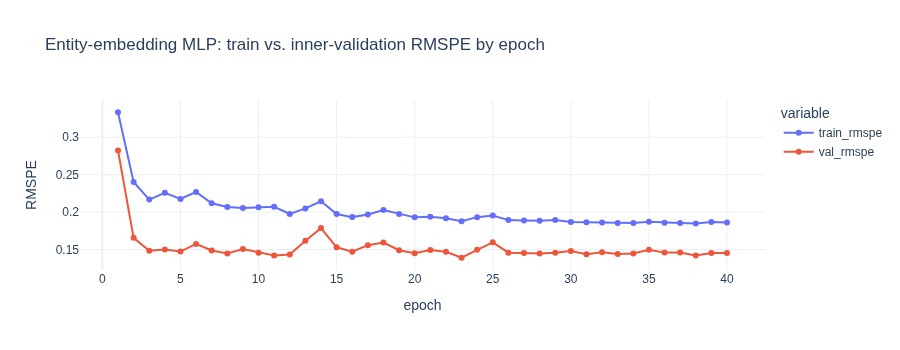

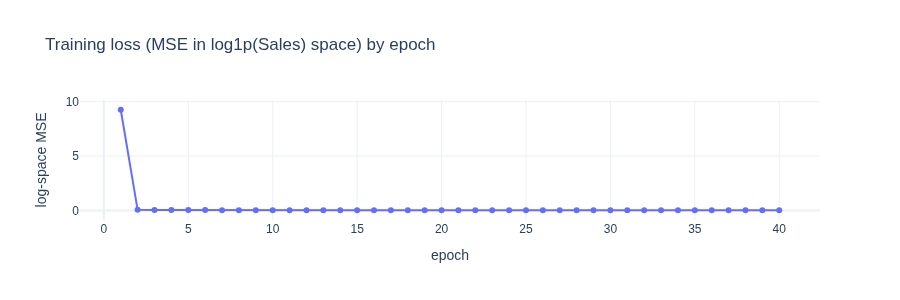

In [7]:
fig = px.line(sweep_history, x="epoch", y=["train_rmspe", "val_rmspe"], markers=True,
              title="Entity-embedding MLP: train vs. inner-validation RMSPE by epoch")
fig.update_layout(height=350, yaxis_title="RMSPE")
fig.show()

fig2 = px.line(sweep_history, x="epoch", y="train_loss_logmse", markers=True,
               title="Training loss (MSE in log1p(Sales) space) by epoch")
fig2.update_layout(height=300, yaxis_title="log-space MSE")
fig2.show()


In [8]:
# Final model: same architecture/budget, trained on the full outer train_fit_feat,
# evaluated on the real held-out val_fold_feat -- best-checkpoint restore handles epoch
# selection automatically, so there's no hyperparameter carried over from the inner
# sweep except the epoch budget itself (40, generously past where the inner sweep's
# best epoch -- 23 -- landed).
model_nn, final_history, final_best_epoch = train_nn(
    CARDINALITIES, NN_CATEGORICAL_COLS, EMB_DIMS, len(NN_NUMERIC_COLS),
    train_cat_codes, train_num, y_train_log, train_fit_feat["Sales"].to_numpy(), train_fit_feat["Open"].to_numpy(),
    val_cat_codes, val_num, val_fold_feat["Sales"].to_numpy(), val_fold_feat["Open"].to_numpy(),
    epochs=40, batch_size=1024,
)

pred_log_nn = predict_in_batches(model_nn, val_cat_codes, val_num)
pred_nn = np.clip(np.expm1(pred_log_nn), 0, None)
pred_nn = np.where(val_fold_feat["Open"].to_numpy() == 0, 0, pred_nn)
rmspe_nn = rmspe(val_fold_feat["Sales"], pred_nn)
print("\nEntity-embedding MLP RMSPE (real val_fold):", round(rmspe_nn, 4))
print("Phase 3 HGB (bar to beat): 0.1412")


epoch   1: log-MSE = 8.90545 | train RMSPE = 0.2471 | val RMSPE = 0.1922 | lr = 1.00e-03 | elapsed 9s


epoch   2: log-MSE = 0.05374 | train RMSPE = 0.2322 | val RMSPE = 0.1665 | lr = 1.00e-03 | elapsed 18s


epoch   3: log-MSE = 0.04265 | train RMSPE = 0.2337 | val RMSPE = 0.1730 | lr = 1.00e-03 | elapsed 26s


epoch   4: log-MSE = 0.03382 | train RMSPE = 0.2210 | val RMSPE = 0.1580 | lr = 1.00e-03 | elapsed 35s


epoch   5: log-MSE = 0.02948 | train RMSPE = 0.2261 | val RMSPE = 0.1720 | lr = 1.00e-03 | elapsed 43s


...

epoch  36: log-MSE = 0.01395 | train RMSPE = 0.1864 | val RMSPE = 0.1483 | lr = 1.56e-05 | elapsed 307s


epoch  37: log-MSE = 0.01399 | train RMSPE = 0.1856 | val RMSPE = 0.1460 | lr = 1.56e-05 | elapsed 315s


epoch  38: log-MSE = 0.01392 | train RMSPE = 0.1852 | val RMSPE = 0.1446 | lr = 1.56e-05 | elapsed 323s


epoch  39: log-MSE = 0.01391 | train RMSPE = 0.1858 | val RMSPE = 0.1472 | lr = 7.81e-06 | elapsed 332s


epoch  40: log-MSE = 0.01398 | train RMSPE = 0.1843 | val RMSPE = 0.1426 | lr = 7.81e-06 | elapsed 341s

restored best checkpoint: epoch 15, val RMSPE = 0.1412

Entity-embedding MLP RMSPE (real val_fold): 0.1412
Phase 3 HGB (bar to beat): 0.1412


In [9]:
val_eval = val_fold_feat.copy()
val_eval["pred_nn"] = pred_nn

def rmspe_by(col, pred_col):
    return pd.Series({k: rmspe(g["Sales"], g[pred_col]) for k, g in val_eval.groupby(col)})

print("Entity-embedding MLP RMSPE by DayOfWeek:")
print(rmspe_by("DayOfWeek", "pred_nn"))

sun = val_eval[val_eval["DayOfWeek"] == 7]
print("\nSunday RMSPE comparison:")
print("  Phase 2 additive+Promo: 0.586")
print("  Phase 3 Ridge+lags: 0.4261 | Random Forest: 0.1825 | HGB: 0.1589")
print(f"  Phase 4 Entity-embedding MLP: {rmspe(sun['Sales'], sun['pred_nn']):.4f}")


Entity-embedding MLP RMSPE by DayOfWeek:
1    0.109155
2    0.130431
3    0.127292
4    0.132974
5    0.187017
6    0.146764
7    0.174133
dtype: float64

Sunday RMSPE comparison:
  Phase 2 additive+Promo: 0.586
  Phase 3 Ridge+lags: 0.4261 | Random Forest: 0.1825 | HGB: 0.1589
  Phase 4 Entity-embedding MLP: 0.1741


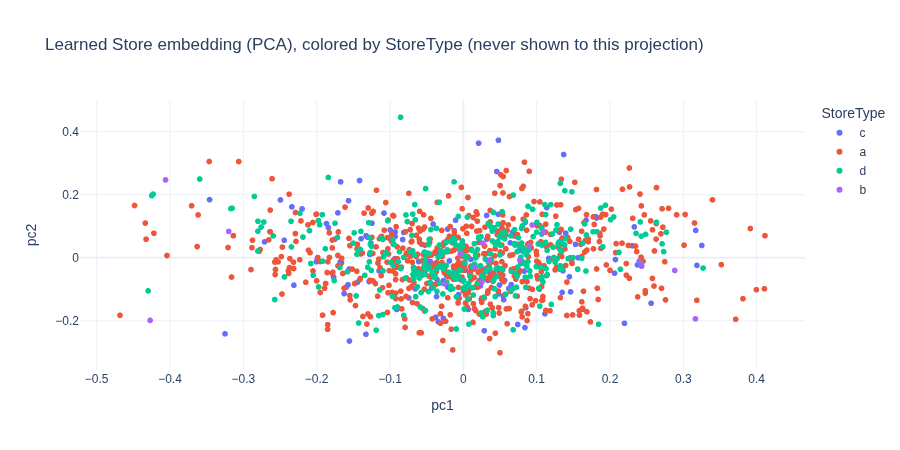

PCA explained variance ratio: [0.34469035 0.20268026]


In [10]:
from sklearn.decomposition import PCA

# Extract the learned Store embedding table and project it to 2D -- a direct, visual
# check of whether the network rediscovered StoreType structure on its own, purely
# from co-occurrence patterns in Sales, without ever being told StoreType at this stage.
store_embed_weights = model_nn.embeddings[NN_CATEGORICAL_COLS.index("Store")].weight.detach().cpu().numpy()
# Row = cat_encoder's ordinal code for a Store; drop the last row (the unused "unknown" slot).
store_ids_by_code = cat_encoder.categories_[NN_CATEGORICAL_COLS.index("Store")]
store_embed_weights = store_embed_weights[:len(store_ids_by_code)]

pca = PCA(n_components=2, random_state=0)
store_embed_2d = pca.fit_transform(store_embed_weights)

embed_df = pd.DataFrame({
    "Store": store_ids_by_code,
    "pc1": store_embed_2d[:, 0],
    "pc2": store_embed_2d[:, 1],
}).merge(store_prepared[["Store", "StoreType"]], on="Store")

fig = px.scatter(embed_df, x="pc1", y="pc2", color="StoreType",
                  title="Learned Store embedding (PCA), colored by StoreType (never shown to this projection)")
fig.update_layout(height=450)
fig.show()
print("PCA explained variance ratio:", pca.explained_variance_ratio_)


In [11]:
from sklearn.metrics import silhouette_score

# A 2D PCA projection retains only ~55% of the embedding's variance (see explained
# variance ratio above), so "do the colors cluster" in that scatter plot is only a
# partial answer. A silhouette score on the FULL 20-dim embedding (not the 2D
# projection) against StoreType labels is a more direct, quantitative check: positive
# means stores of the same type sit closer to each other than to other types on
# average; 0 means no structure; negative means the labeling is actively worse than
# random groupings.
labels = embed_df["StoreType"].to_numpy()
sil = silhouette_score(store_embed_weights, labels)
print(f"Silhouette score of the full 20-dim Store embedding, grouped by StoreType: {sil:.4f}")


Silhouette score of the full 20-dim Store embedding, grouped by StoreType: -0.0401


Saved phase4_nn_results.csv, phase4_val_predictions.csv


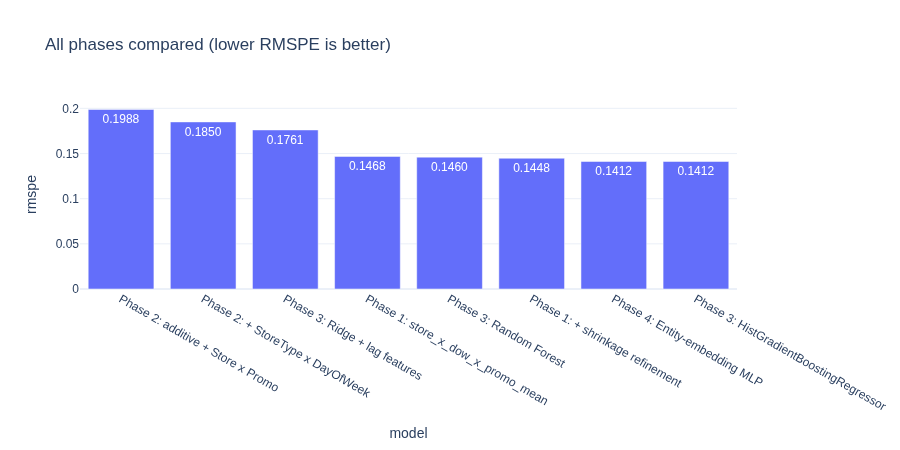

In [12]:
results_df = pd.DataFrame([
    {"model": "Phase 1: store_x_dow_x_promo_mean", "rmspe": 0.1468},
    {"model": "Phase 1: + shrinkage refinement", "rmspe": 0.1448},
    {"model": "Phase 2: additive + Store x Promo", "rmspe": 0.1988},
    {"model": "Phase 2: + StoreType x DayOfWeek", "rmspe": 0.185},
    {"model": "Phase 3: Ridge + lag features", "rmspe": 0.1761},
    {"model": "Phase 3: Random Forest", "rmspe": 0.146},
    {"model": "Phase 3: HistGradientBoostingRegressor", "rmspe": 0.1412},
    {"model": "Phase 4: Entity-embedding MLP", "rmspe": rmspe_nn},
])
results_df.to_csv("phase4_nn_results.csv", index=False)

val_preds = val_fold_feat[["Store", "Date", "Sales", "Open"]].copy()
val_preds["pred_nn"] = pred_nn
val_preds.to_csv("phase4_val_predictions.csv", index=False)
print("Saved phase4_nn_results.csv, phase4_val_predictions.csv")

fig = px.bar(results_df.sort_values("rmspe", ascending=False), x="model", y="rmspe",
             title="All phases compared (lower RMSPE is better)", text_auto=".4f")
fig.update_layout(height=450)
fig.show()


## Summary

The entity-embedding MLP reaches RMSPE 0.1412 on the real held-out `val_fold` -- an exact tie with Phase 3's HGB, not an improvement. Given identical lag/rolling features and the same frozen-cutoff split, a fundamentally different modeling paradigm (learned dense representations instead of one-hot or target-encoding) converges to the same performance ceiling rather than breaking past it.

Per-day breakdown tells a more nuanced story than the headline number: the MLP's Sunday RMSPE (0.1741) is worse than HGB's (0.1589), and its worst day is actually Friday (0.187), not Sunday -- a different failure pattern than every tree/linear model so far, even though the overall RMSPE lands in the same place.

The Store embedding does not visibly encode `StoreType`: a silhouette score of -0.04 on the full 20-dimensional embedding (measured directly, not eyeballed off the 2D PCA projection, which only retains ~55% of the embedding's variance) shows no meaningful StoreType clustering. A plausible explanation is that the rich lag/rolling sales history already carries most of each store's identity signal, leaving the embedding to encode residual variation rather than store type itself -- but this is model behavior worth noting as an open question, not a settled explanation.

Given that entity embeddings + MLP match but don't beat gradient boosting here, and Phase 3's tree ensembles already closed most of the gap over Phase 1's baseline, the practical case for preferring this architecture over HGB (given its added engineering and training-time cost) is weak for this dataset and feature set.